# ShootArchitecture: Adel's wheat shoots in metafspm

ShootArchitecture (`openalea.adel.architecture`) is the port of Adel's shoot architecture (its `AdelDyn`) to a metafspm
`StructuralComponent`:
- the plants' topology in metafspm's MPG: axes, phytomers, organs, elements;
- the organs' dimensions and leaf shapes, read from Adel's tables;
- the elements derived from the organs' lengths;
- their placement by Adel's turtle and their triangles, for light models and display.

It does not decide how the organs grow. Development and senescence models write the organs' lengths, as cnwgrass
writes them to `AdelDyn` in Wheat-BRIDGES. This tutorial uses `GivenDevelopment`, a small component that gives the
lengths from a fixed scenario.

The steps:
1. Adel's tables and a canopy of 20 plants;
2. growing it, and reading its structure;
3. drawing the canopy;
4. the coupling contract: what development models write, and what light models read;
5. the comparison with the legacy, and the speed.

Lengths are in m, thermal time in °Cd.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from openalea.adel.comparison.given_development import GivenShoot
from openalea.adel.comparison.legacy_run import harness_tables
from openalea.adel.comparison.port_run import leaf_shapes, organ_names, sown_stand
from openalea.adel.display import draw, state_colors, value_colors
from openalea.metafspm.scene.scene import Scene

## 1. Adel's tables and a canopy

ShootArchitecture reads Adel's two tables, with lengths in cm:
- the **axes table** (Adel's `axeT`): one row per axis of each plant, with its final leaf number `nf` and its first
  leaf's emergence `emf1` (°Cd);
- the **phytomer table** (Adel's `phytoT`): one row per axis and rank, with the blade's length `Ll` and width `Lw`, the
  sheath's `Gl`, `Gd`, the internode's `El`, `Ed`, and the leaf shape's indices `Lindex`, `Lseed`.

Here they are the comparison harness' tables: Adel's samples, a main stem and four tillers (T1 to T4).

In [2]:
axes_table, phytomer_table = harness_tables("echap")
axes_table[["plant", "axe", "nf", "emf1", "HS_final"]]

,plant,axe,nf,emf1,HS_final
0,1,MS,12.0,21.543097,12.0
1,1,T1,9.0,161.522819,NaN
2,1,T2,8.0,256.091716,NaN
3,1,T3,7.0,327.074709,NaN
4,1,T4,6.0,424.385645,NaN


In [3]:
phytomer_table.loc[phytomer_table["axe"] == "MS", ["axe", "n", "Ll", "Lw", "Gl", "Gd", "El", "Ed", "Lindex", "Lseed"]]

,axe,n,Ll,Lw,Gl,Gd,El,Ed,Lindex,Lseed
0,MS,1,9.733180,0.459954,2.228428,0.183662,0.000000,0.000000,1,1
1,MS,2,8.256204,0.444063,2.334653,0.199892,0.000000,0.000000,1,1
2,MS,3,6.822363,0.426528,2.494112,0.215413,0.000000,0.000000,1,1
3,MS,4,6.502344,0.431675,2.787851,0.231162,0.000000,0.000000,1,1
4,MS,5,7.452413,0.491038,3.502955,0.248718,0.000000,0.000000,1,1
5,MS,6,9.265873,0.620232,4.977466,0.261250,0.000000,0.000000,1,1
6,MS,7,11.881087,0.811207,7.112362,0.271246,0.000000,0.000000,1,1
7,MS,8,14.954656,1.031545,9.232181,0.292957,1.266667,0.023794,2,1
8,MS,9,17.508110,1.234782,10.620333,0.330251,4.850000,0.091105,2,1
9,MS,10,18.939615,1.389160,11.279239,0.357112,8.666667,0.162799,2,1


A metafspm scene starts from a planting table: one row per plant, with its plant model, its position (m), its rotation
(°) and its scenario's parameters. The plant model `GivenShoot` runs `GivenDevelopment` and then ShootArchitecture.

The 20 plants are sown in four rows 15 cm apart, with random azimuths. Each plant is given a random delay of up to
60 °Cd in its development. The leaf shapes are echap's, which change with the blade's age. They are fitted once and
shared by every plant.

In [4]:
stand = sown_stand(20, n_rows=4, row_spacing=15., plant_spacing=4., max_delay=60., seed=0)
shared = dict(axes_table=axes_table, phytomer_table=phytomer_table, table_plant=1, leaves=leaf_shapes("echap"),
              n_sect=2, thermal_time_step=10.)
planting = pd.DataFrame([dict(plant=f"p{k}", model=GivenShoot, x=plant.x * 0.01, y=plant.y * 0.01, z=0.,
                              rotation=plant.azimuth, scenario={"parameters": dict(shared, delay=plant.delay)})
                         for k, plant in enumerate(stand)])
planting.attrs.update(xrange=0.4, yrange=0.6)
scene = Scene(planting, time_step=3600)
ds = scene.populations[0].data_structure
architecture = scene.populations[0].instance.architecture
planting[["plant", "x", "y", "rotation"]].head()

,plant,x,y,rotation
0,p0,0.000629,-0.000661,14.750469
1,p1,0.037322,0.001808,218.388879
2,p2,0.076481,-0.006327,293.707279
3,p3,0.108375,-0.001094,262.675961
4,p4,0.157279,-0.001582,107.896281


## 2. Growing the canopy

Each `scene.run()` is one call of each component. `GivenDevelopment` advances each plant's thermal time by
`thermal_time_step` (10 °Cd), and writes:
- the number of axes emerged per plant;
- the number of phytomers per axis;
- each organ's length, visible length and senesced length, and each blade's age.

ShootArchitecture then creates the phytomers asked for, derives the elements and places them.

In [5]:
snapshots, history = {}, []
for step in range(121):
    scene.run()
    history.append(dict(thermal_time=step * 10., organs=len(ds.entity_ids("Organ")), elements=ds.n_nodes(),
                        green_area=np.sum(ds.get("green_area")), senesced_area=np.sum(ds.get("senesced_area"))))
    if step in (40, 80, 120):
        snapshots[step] = (architecture.triangles(), np.asarray(ds.get("is_green")).copy())
history = pd.DataFrame(history)
history.iloc[::20]

,thermal_time,organs,elements,green_area,senesced_area
0,0.0,60,140,0.000000,0.000000
20,200.0,207,483,0.011614,0.000000
40,400.0,660,1540,0.038308,0.000000
60,600.0,1350,3150,0.075665,0.003104
80,800.0,2043,4767,0.112608,0.020535
100,1000.0,2487,5803,0.175264,0.053502
120,1200.0,2520,5880,0.180567,0.100188


The structure is in the MPG: Plant, then Axis, GrowthUnit, Phytomer, Organ (StemInternode, Sheath, Blade), and
SubOrgan, the elements. Each organ has a hidden element and visible ones; a blade has `n_sect` of these (here 2).
The variables are arrays on the DataStructure, one value per entity of their scale.

Here are the organs of the first plant's main stem:

In [6]:
first_plant = ds.map_to(np.arange(len(ds.entity_ids("Plant")), dtype=float), "Plant", "Organ", "broadcast") == 0
main_stem = ds.map_to((np.asarray(ds.get("bearer_row")) < 0).astype(float), "Axis", "Organ", "broadcast") > 0
organs = pd.DataFrame({name: np.asarray(ds.get(name)) for name in
                       ("organ_rank", "organ_length", "visible_length", "organ_senesced_length", "organ_area",
                        "shape_mature_length", "shape_max_width")})
organs.insert(0, "organ", organ_names(ds))
organs[first_plant & main_stem].sort_values(["organ_rank", "organ"]).head(12)

,organ,organ_rank,organ_length,visible_length,organ_senesced_length,organ_area,shape_mature_length,shape_max_width
2,blade,1,0.097332,0.097332,0.097332,0.000355,0.097332,0.004600
0,internode,1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,sheath,1,0.022284,0.022284,0.000000,0.000129,0.000000,0.000000
62,blade,2,0.082562,0.060278,0.082562,0.000199,0.082562,0.004441
60,internode,2,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
61,sheath,2,0.023347,0.001062,0.000000,0.000007,0.000000,0.000000
161,blade,3,0.068224,0.044877,0.068224,0.000137,0.068224,0.004265
159,internode,3,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
160,sheath,3,0.024941,0.001595,0.000000,0.000011,0.000000,0.000000
314,blade,4,0.065023,0.040082,0.065023,0.000121,0.065023,0.004317


## 3. Drawing the canopy

`architecture.triangles()` gives every triangle of the canopy, as metafspm's `Triangles`:
- `vertices`, shape (T, 3, 3), in the scene's frame, in m;
- `owner`, shape (T,), the node index of the element each triangle belongs to.

Stem elements are drawn as slim cylinders. A blade element is drawn as its rolled part's cylinder, then its flat
part's mesh, made from its leaf shape. `openalea.adel.display` draws them with matplotlib, without PlantGL, coloured
here by each element's state: green, or straw when more senesced than green.

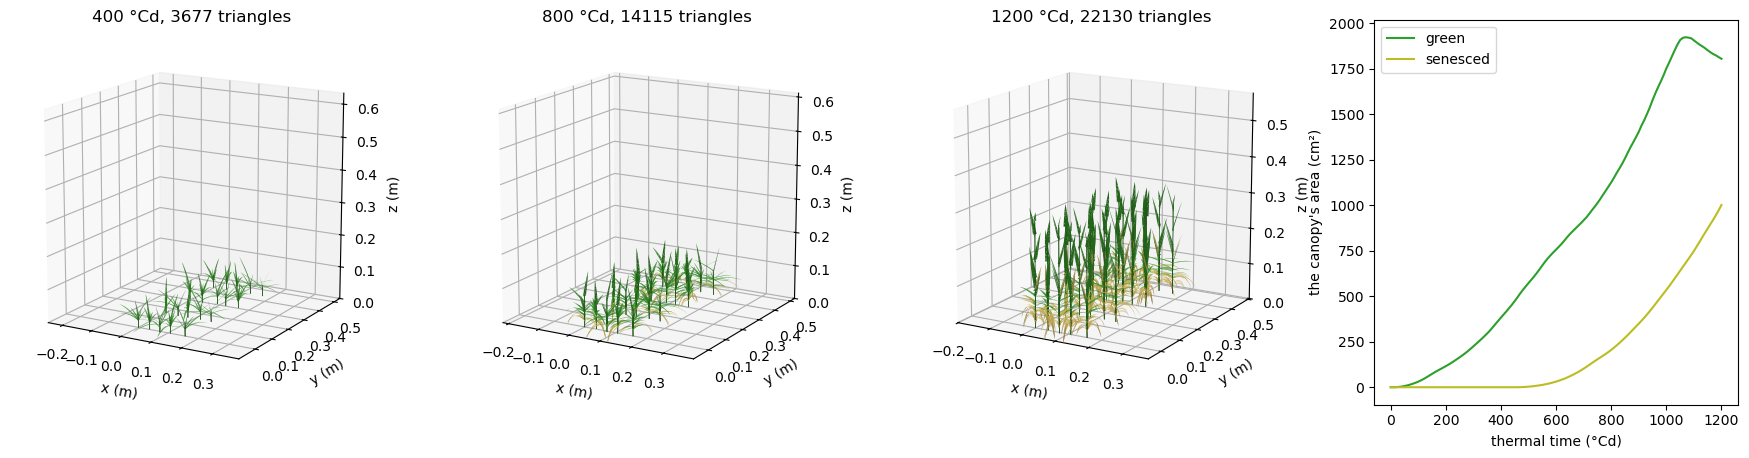

In [7]:
figure = plt.figure(figsize=(18, 5))
for k, (step, (triangles, is_green)) in enumerate(snapshots.items()):
    axes = figure.add_subplot(1, 4, k + 1, projection="3d")
    draw(axes, triangles, colors=state_colors(is_green))
    axes.set_title(f"{step * 10:.0f} °Cd, {len(triangles)} triangles")
axes = figure.add_subplot(1, 4, 4)
axes.plot(history["thermal_time"], history["green_area"] * 1e4, color="tab:green", label="green")
axes.plot(history["thermal_time"], history["senesced_area"] * 1e4, color="tab:olive", label="senesced")
axes.set_xlabel("thermal time (°Cd)")
axes.set_ylabel("the canopy's area (cm²)")
axes.legend()
figure.subplots_adjust(left=0.02, right=0.98, wspace=0.25)

## 4. The coupling contract

**What development and senescence models write** (per entity, on the DataStructure):

| scale | variable | meaning |
|---|---|---|
| Plant | `axis_number` | its axes emerged, in its axes table's order |
| Axis | `phytomer_number` | its phytomers initiated |
| Organ | `organ_length`, `visible_length` | its length, and its length out of the sheaths' tube |
| Organ | `rolled_length`, `age` | a blade's rolled length, and its age (which picks its shape's age class) |
| Organ | `shape_mature_length`, `shape_max_width` | optional: a blade's final dimensions; the phytomer table's by default |
| Organ | `organ_senesced_length` | its senesced length (written by a senescence model) |

The elements belong to ShootArchitecture: it derives them at each call, and the other models read them.

For instance, a development model that gives the blades a 20 % larger width than the phytomer table. ShootArchitecture
takes the new width at its next call: the blades' areas and their meshes change.

In [8]:
blade = organ_names(ds) == "blade"
area_before = np.sum(np.asarray(ds.get("organ_area"))[blade])
widths = np.array(ds.get("shape_max_width"), dtype=float)
ds.set("shape_max_width", np.where(blade, widths * 1.2, widths))
architecture()
print(f"the blades' area: {area_before * 1e4:.1f} cm² -> {np.sum(np.asarray(ds.get('organ_area'))[blade]) * 1e4:.1f} cm²")
ds.set("shape_max_width", widths)
architecture()

the blades' area: 2025.2 cm² -> 2430.3 cm²


**What light models read:** the triangles and their owners. A light model computes a value per triangle and gives it
back per element with `Triangles.per_owner`, which sums per node index. Caribu, once ported, will follow this
contract.

Here is a toy model: Beer's law in 5 cm columns. Each triangle receives exp(-0.5 · A / a), where A is the projected
area of the triangles above it in its column and a is the column's ground area.

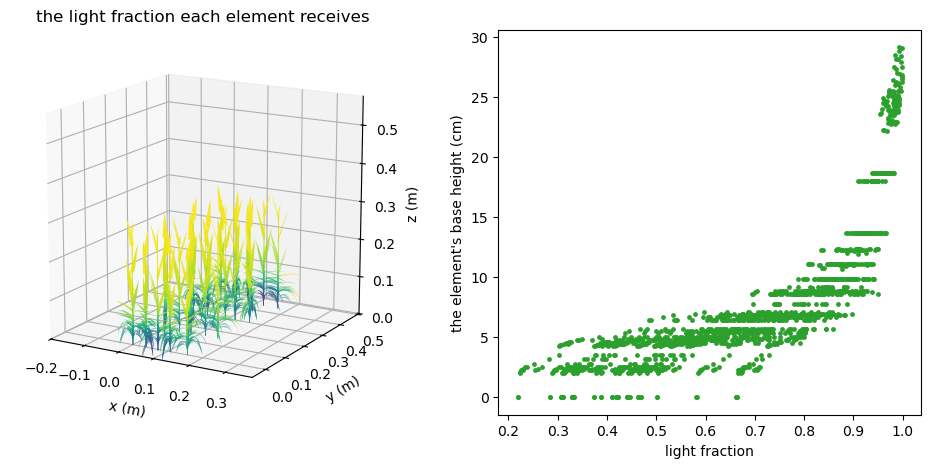

In [9]:
def light_fraction(triangles, n_elements, extinction=0.5, column_width=0.05):
    centre = triangles.vertices.mean(axis=1)
    side = triangles.vertices[:, 1, :2] - triangles.vertices[:, 0, :2]
    other = triangles.vertices[:, 2, :2] - triangles.vertices[:, 0, :2]
    projected = 0.5 * np.abs(side[:, 0] * other[:, 1] - side[:, 1] * other[:, 0])
    _, column = np.unique(np.floor(centre[:, :2] / column_width).astype(int), axis=0, return_inverse=True)
    column = column.reshape(-1)
    above = np.array([projected[(column == column[i]) & (centre[:, 2] > centre[i, 2])].sum()
                      for i in range(len(projected))])
    fraction = np.exp(-extinction * above / column_width ** 2)
    areas = triangles.areas()
    total = triangles.per_owner(areas, n_elements)
    return np.where(total > 0, triangles.per_owner(fraction, n_elements, weights=areas) / np.where(total > 0, total, 1.),
                    0.)


triangles = architecture.triangles()
fraction = light_fraction(triangles, ds.n_nodes())
figure = plt.figure(figsize=(12, 5))
axes = figure.add_subplot(1, 2, 1, projection="3d")
draw(axes, triangles, colors=value_colors(fraction, limits=(0., 1.)), shade=False)
axes.set_title("the light fraction each element receives")
axes = figure.add_subplot(1, 2, 2)
green = np.asarray(ds.get("green_area")) > 0
axes.scatter(fraction[green], np.asarray(ds.get("z1"))[green] * 100, s=6, c="tab:green")
axes.set_xlabel("light fraction")
axes.set_ylabel("the element's base height (cm)");

`example/light_coupling.py` makes this toy light model a metafspm component (`ToyLight`). It runs in the plant model
after the shoot, and writes each element's light fraction and absorbed light on the DataStructure.

## 5. The comparison with the legacy, and the speed

`openalea.adel.comparison` runs the frozen legacy (`openalea.adel.legacy.adel_dynamic.AdelDyn`) and the port on the
same scenario. The tests in `test/comparison` compare the topology, the elements' lengths and areas, the anchor points
and every triangle, step by step, on one plant and on a stand of four plants. They agree to 1e-10 m.

Here are the two canopies side by side: four plants after 900 °Cd. The legacy's triangles are drawn as its turtle
placed them. The legacy's `update_geometry` then places each plant a second time: it translates the plant by its
position again, and rotates it by its azimuth's degrees read as radians.

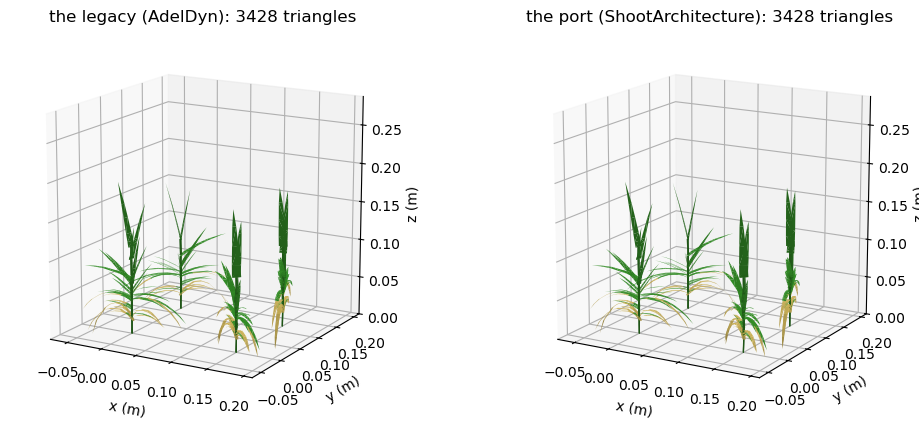

In [10]:
from openalea.adel.comparison.legacy_run import Planting, legacy_canopy, legacy_run
from openalea.adel.comparison.port_run import port_run

plants = [Planting(0., 0., 0., 0.), Planting(15., 0., 40., 30.), Planting(0., 12., 130., 60.),
          Planting(15., 12., 250., 15.)]
options = dict(n_steps=90, leaves="echap", n_sect=2, plants=plants, record_every=90)
legacy, port = legacy_run(**options), port_run(**options)
legacy_vertices, legacy_green = legacy_canopy(legacy.steps[-1], plants)
port_triangles = port.scene.populations[0].instance.architecture.triangles()
port_green = np.asarray(port.scene.populations[0].data_structure.get("is_green"))

figure = plt.figure(figsize=(12, 5))
for k, (title, vertices, colors) in enumerate((("the legacy (AdelDyn)", legacy_vertices, state_colors(legacy_green)),
                                               ("the port (ShootArchitecture)", port_triangles.vertices,
                                                state_colors(port_green)[port_triangles.owner]))):
    axes = figure.add_subplot(1, 2, k + 1, projection="3d")
    draw(axes, vertices, triangle_colors=colors)
    axes.set_title(f"{title}: {len(vertices)} triangles")

The speed: 60 steps of both models on stands of 1 and 4 plants, with the geometry computed at every step, as a light
model coupled at each step needs it. The port's lead grows with the plants' size and number:
`example/comparison/profile_population.py` runs the full profile, up to 16 plants.

In [11]:
import sys
sys.path.insert(0, "../comparison")
from profile_population import legacy_time, port_time, stand

port_time(stand(1), 2)                                   # numba's compilations aside
rows = []
for n_plants in (1, 4):
    legacy_seconds, _ = legacy_time(stand(n_plants), 60)
    stepping, meshing, _ = port_time(stand(n_plants), 60)
    rows.append(dict(plants=n_plants, legacy=legacy_seconds, port=stepping + meshing,
                     speed_up=legacy_seconds / (stepping + meshing)))
pd.DataFrame(rows).round(2)

,plants,legacy,port,speed_up
0,1,0.35,0.13,2.70
1,4,1.27,0.23,5.51


## Where next

- `example/canopy.py` and `example/light_coupling.py`: the canopy and the light coupling above, as scripts;
- `example/comparison/`: the side-by-side drawing and the profile;
- the module documentation of `openalea.adel.architecture`: the structure, the variables, the coupling contract.

Adel's QuickStart notebook (`example/legacy/notebook`) still runs the legacy, with AdelWheat's R kinetics. These are
not ported: in metafspm, the organs' lengths come from development models.